alyssa zahra maharani asriandy

2300015003

In [ ]:
%pip install wget

from pathlib import Path
import os

os.environ["KERAS_HOME"] = str(Path.cwd() / ".tools" / "keras")

import zipfile
import wget
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

tf.keras.utils.set_random_seed(42)

gpus = tf.config.list_physical_devices("GPU")
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)

print("TensorFlow:", tf.__version__)
print("GPU:", gpus if gpus else "Tidak terdeteksi; pelatihan menggunakan CPU.")

IMG_SIZE = (224, 224)
BATCH_SIZE = 16
EPOCHS = 50

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for wget: filename=wget-3.2-py3-none-any.whl size=9686 sha256=7a6ae98a20cc786419814bcb3c7e4e8cbed11eac38977fcda3d812f17dce452d
  Stored in directory: /root/.cache/pip/wheels/8a/b8/04/0c88fb22489b0c049bee4e977c5689c7fe597d6c4b0e7d0b6a
Successfully built wget
TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
url = "https://mymldatasets.s3.eu-de.cloud-object-storage.appdomain.cloud/UCMerced_LandUse.zip"

data_dir = Path("data")
data_dir.mkdir(exist_ok=True)

zip_path = data_dir / "UCMerced_LandUse.zip"

if not zip_path.exists():
    wget.download(url, out=str(zip_path))

with zipfile.ZipFile(zip_path) as arsip:
    for nama in arsip.namelist():
        tujuan = (data_dir / nama).resolve()
        if not tujuan.is_relative_to(data_dir.resolve()):
            raise ValueError("Lokasi file ZIP tidak valid")

    arsip.extractall(data_dir)

image_dir = data_dir / "dataset" / "Images"

print("Folder gambar:", image_dir)

Folder gambar: data/dataset/Images


In [ ]:
nama_kelas = sorted(
    folder.name for folder in image_dir.iterdir()
    if folder.is_dir()
)

gambar, label = [], []

for kelas, nama in enumerate(nama_kelas):
    for path in sorted((image_dir / nama).glob("*.tif")):
        with Image.open(path) as img:
            img = img.convert("RGB").resize(
                IMG_SIZE,
                Image.Resampling.BILINEAR)
            gambar.append(np.asarray(img))
        label.append(kelas)

X = np.asarray(gambar, dtype="uint8")
y = np.asarray(label, dtype="int32")

del gambar

assert len(nama_kelas) == 21 and len(X) == 2100, \
    "Periksa kelengkapan dataset"

assert np.all(np.bincount(y) == 100), \
    "Setiap kelas seharusnya memiliki 100 gambar"

print("Bentuk data:", X.shape)
print("Kelas:", nama_kelas)

Bentuk data: (2100, 224, 224, 3)
Kelas: ['agricultural', 'airplane', 'baseballdiamond', 'beach', 'buildings', 'chaparral', 'denseresidential', 'forest', 'freeway', 'golfcourse', 'harbor', 'intersection', 'mediumresidential', 'mobilehomepark', 'overpass', 'parkinglot', 'river', 'runway', 'sparseresidential', 'storagetanks', 'tenniscourt']


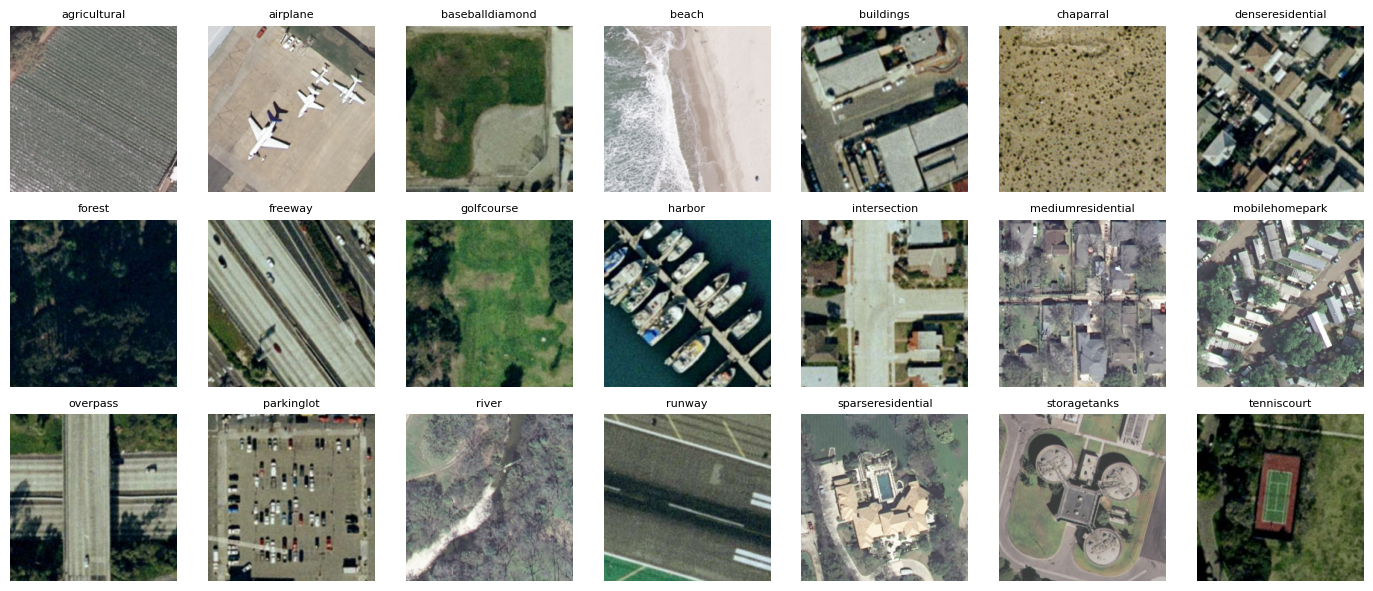

In [ ]:
fig, axes = plt.subplots(3, 7, figsize=(14, 6))

for kelas, ax in enumerate(axes.flat):
    idx = np.flatnonzero(y == kelas)[0]
    ax.imshow(X[idx])
    ax.set_title(nama_kelas[kelas], fontsize=8)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
x_train, x_sisa, y_train, y_sisa = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=42
)

x_val, x_test, y_val, y_test = train_test_split(
    x_sisa,
    y_sisa,
    test_size=0.50,
    stratify=y_sisa,
    random_state=42
)

print(
    "Train:",
    len(y_train),
    "Validation:",
    len(y_val),
    "Test:",
    len(y_test)
)

Train: 1470 Validation: 315 Test: 315


In [ ]:
# AlexNet tidak tersedia di tf.keras.applications, jadi dibangun manual
# dan dilatih dari nol (tanpa bobot ImageNet).
# Perbedaan dari paper asli: BatchNormalization menggantikan LRN,
# dan augmentasi ditambahkan karena data latih hanya 1.470 gambar.
augmentasi = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal_and_vertical"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
], name="augmentasi")

inputs = tf.keras.Input(shape=(*IMG_SIZE, 3))

x = tf.keras.layers.Rescaling(1.0 / 255)(inputs)
x = augmentasi(x)

# Conv1
x = tf.keras.layers.Conv2D(96, 11, strides=4, activation="relu")(x)
x = tf.keras.layers.BatchNormalization()(x)
x = tf.keras.layers.MaxPooling2D(pool_size=3, strides=2)(x)

# Conv2
x = tf.keras.layers.Conv2D(256, 5, padding="same", activation="relu")(x)
x = tf.keras.layers.BatchNormalization()(x)
x = tf.keras.layers.MaxPooling2D(pool_size=3, strides=2)(x)

# Conv3 - Conv5
x = tf.keras.layers.Conv2D(384, 3, padding="same", activation="relu")(x)
x = tf.keras.layers.Conv2D(384, 3, padding="same", activation="relu")(x)
x = tf.keras.layers.Conv2D(256, 3, padding="same", activation="relu")(x)
x = tf.keras.layers.MaxPooling2D(pool_size=3, strides=2)(x)

# Fully connected
x = tf.keras.layers.Flatten()(x)
x = tf.keras.layers.Dense(4096, activation="relu")(x)
x = tf.keras.layers.Dropout(0.5)(x)
x = tf.keras.layers.Dense(4096, activation="relu")(x)
x = tf.keras.layers.Dropout(0.5)(x)

outputs = tf.keras.layers.Dense(
    len(nama_kelas),
    activation="softmax"
)(x)

model = tf.keras.Model(
    inputs,
    outputs,
    name="alexnet_ucmerced"
)

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-4),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

print("Model dilatih dari nol (tanpa pretrained)")

Model: "alexnet_ucmerced"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentasi (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 54, 54, 96)     │        34,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 54, 54, 96)     │           384 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 26, 26, 96)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 26, 26, 256)    │       614,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 26, 26, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 384)    │       885,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 12, 12, 384)    │     1,327,488 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 12, 12, 256)    │       884,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 5, 5, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6400)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4096)           │    26,218,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4096)           │    16,781,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 21)             │        86,037 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 46,834,453 (178.66 MB)

 Trainable params: 46,833,749 (178.66 MB)

 Non-trainable params: 704 (2.75 KB)

Model dilatih dari nol (tanpa pretrained)


In [ ]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True
)

history = model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stop],
    verbose=2
)

print("Epoch dijalankan:", len(history.history["loss"]))

Epoch 1/50
92/92 - 15s - 161ms/step - accuracy: 0.1776 - loss: 2.7949 - val_accuracy: 0.0476 - val_loss: 3.5460
Epoch 2/50
92/92 - 5s - 54ms/step - accuracy: 0.3313 - loss: 2.1322 - val_accuracy: 0.0476 - val_loss: 4.0290
Epoch 3/50
92/92 - 5s - 53ms/step - accuracy: 0.4041 - loss: 1.8497 - val_accuracy: 0.0984 - val_loss: 3.5544
Epoch 4/50
92/92 - 5s - 55ms/step - accuracy: 0.4707 - loss: 1.6711 - val_accuracy: 0.1651 - val_loss: 3.4749
Epoch 5/50
92/92 - 5s - 55ms/step - accuracy: 0.5034 - loss: 1.5017 - val_accuracy: 0.2794 - val_loss: 2.6141
Epoch 6/50
92/92 - 5s - 55ms/step - accuracy: 0.5531 - loss: 1.3468 - val_accuracy: 0.3365 - val_loss: 2.5435
Epoch 7/50
92/92 - 5s - 53ms/step - accuracy: 0.6041 - loss: 1.2312 - val_accuracy: 0.2825 - val_loss: 2.6602
Epoch 8/50
92/92 - 5s - 55ms/step - accuracy: 0.6497 - loss: 1.0702 - val_accuracy: 0.3619 - val_loss: 2.4934
Epoch 9/50
92/92 - 5s - 55ms/step - accuracy: 0.6810 - loss: 0.9583 - val_accuracy: 0.4635 - val_loss: 1.7512
Epoch 10

Test loss: 1.2182 | Test accuracy: 69.84%
                   precision    recall  f1-score   support

     agricultural       0.86      0.80      0.83        15
         airplane       0.67      0.93      0.78        15
  baseballdiamond       0.82      0.93      0.88        15
            beach       0.83      1.00      0.91        15
        buildings       0.19      0.20      0.19        15
        chaparral       1.00      0.93      0.97        15
 denseresidential       0.38      0.20      0.26        15
           forest       0.85      0.73      0.79        15
          freeway       0.58      0.93      0.72        15
       golfcourse       0.83      0.67      0.74        15
           harbor       1.00      0.93      0.97        15
     intersection       0.77      0.67      0.71        15
mediumresidential       0.88      0.47      0.61        15
   mobilehomepark       0.60      1.00      0.75        15
         overpass       0.53      0.60      0.56        15
       parkin

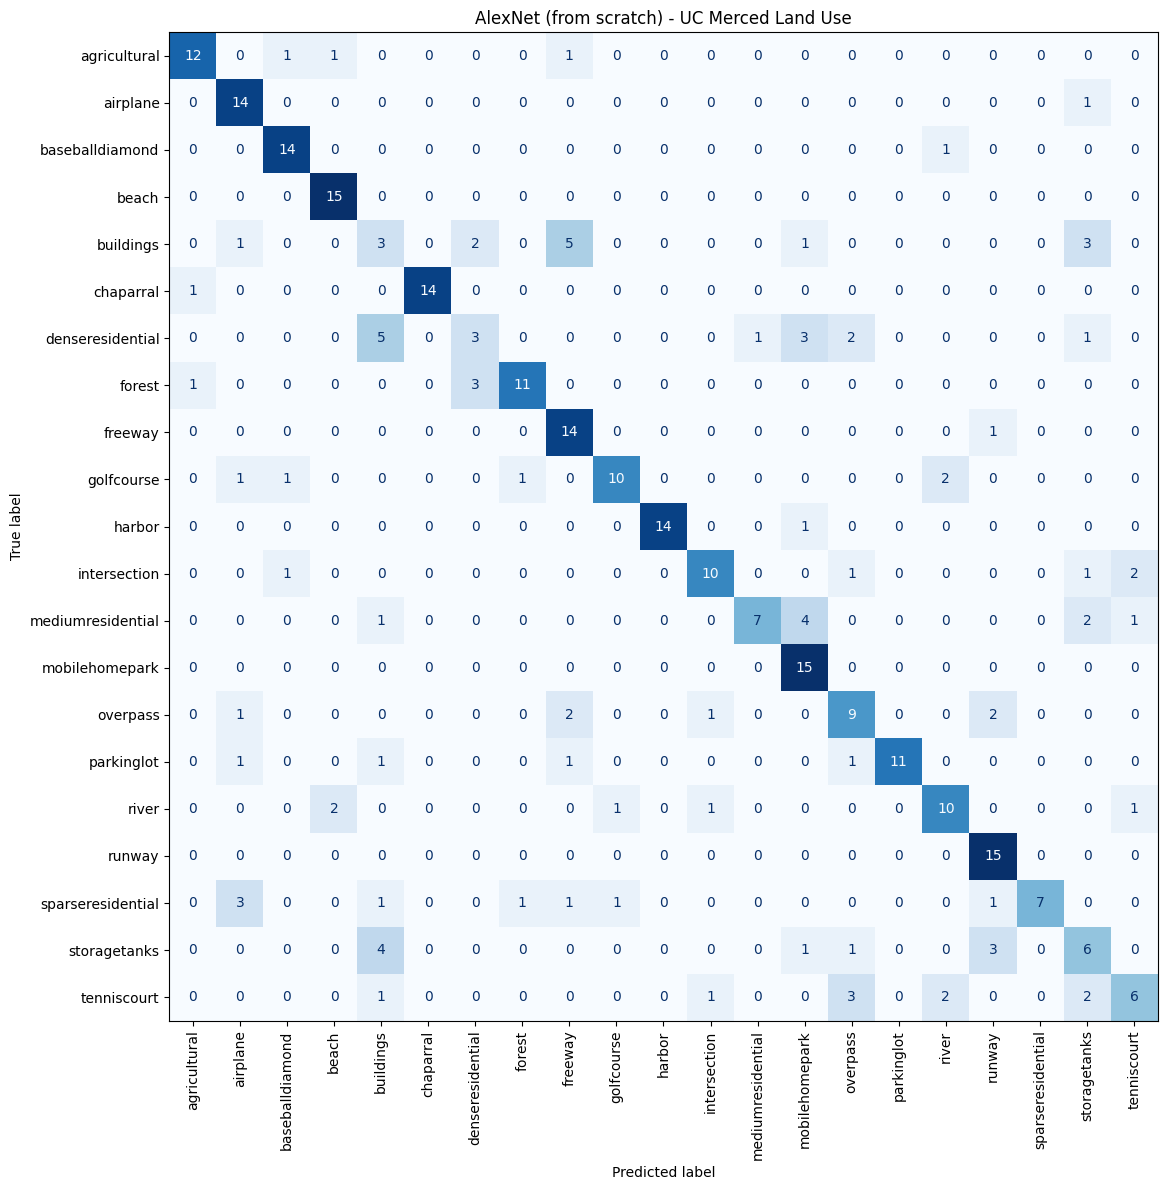

In [ ]:
test_loss, test_acc = model.evaluate(
    x_test,
    y_test,
    verbose=0
)

probabilitas = model.predict(
    x_test,
    batch_size=BATCH_SIZE,
    verbose=0
)

y_pred = probabilitas.argmax(axis=1)

print(
    f"Test loss: {test_loss:.4f} | "
    f"Test accuracy: {test_acc:.2%}"
)

assert np.isclose(
    test_acc,
    np.mean(y_pred == y_test),
    atol=1e-6
)

print(
    classification_report(
        y_test,
        y_pred,
        target_names=nama_kelas,
        zero_division=0
    )
)

fig, ax = plt.subplots(figsize=(14, 12))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=nama_kelas,
    cmap="Blues",
    xticks_rotation=90,
    colorbar=False,
    ax=ax
)

ax.set_title("AlexNet (from scratch) - UC Merced Land Use")

plt.tight_layout()
plt.show()

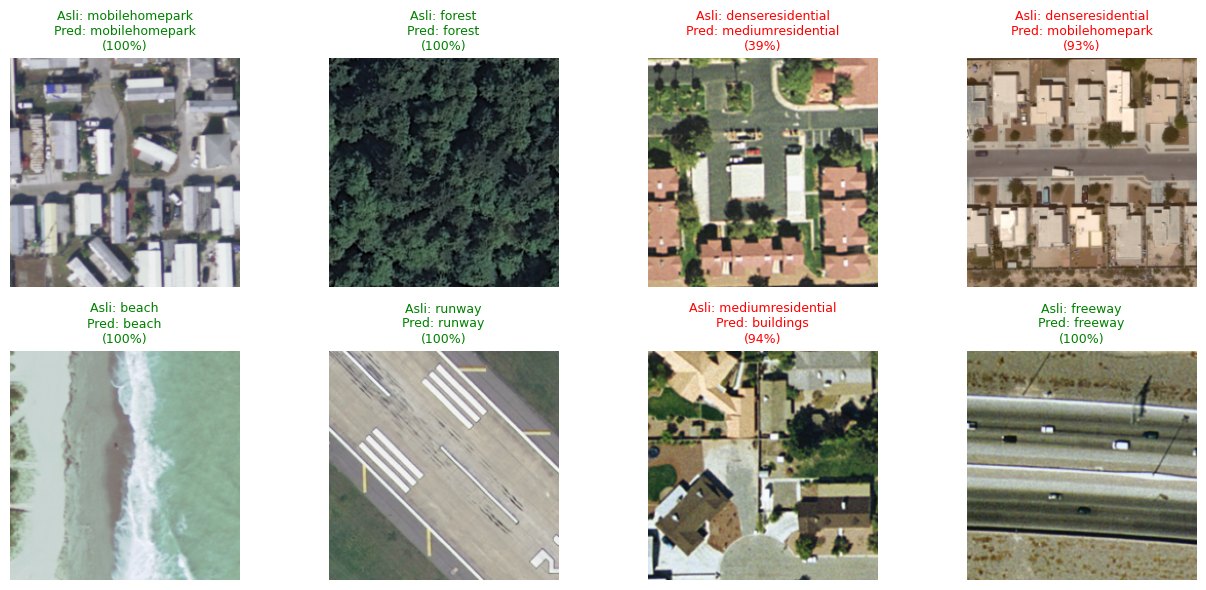

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(13, 6))

for i, ax in enumerate(axes.flat):
    ax.imshow(x_test[i])
    ax.set_title(
        f"Asli: {nama_kelas[y_test[i]]}\n"
        f"Pred: {nama_kelas[y_pred[i]]}\n"
        f"({probabilitas[i].max():.0%})",
        fontsize=9,
        color="green" if y_test[i] == y_pred[i] else "red"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()